In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

#read training data
train = pd.read_csv('/kaggle/input/nexar-collision-prediction/train.csv')
train

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,time_of_event,time_of_alert,target
0,1924,NaN,NaN,0
1,822,19.500,18.633,1
2,1429,NaN,NaN,0
3,208,19.800,19.233,1
4,1904,NaN,NaN,0
...,...,...,...,...
1495,500,19.933,18.633,1
1496,519,19.567,19.033,1
1497,262,17.900,13.933,1
1498,391,19.867,19.267,1


In [2]:
#read test data for later
test = pd.read_csv('/kaggle/input/nexar-collision-prediction/test.csv')
test

,id
0,204
1,30
2,146
3,20
4,511
...,...
1339,2621
1340,2858
1341,2625
1342,2791


In [3]:
safe = train[train['target'] == 0]
safe.describe()

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,time_of_event,time_of_alert,target
count,750.000000,0.0,0.0,750.0
mean,1595.452000,NaN,NaN,0.0
std,313.314751,NaN,NaN,0.0
min,1040.000000,NaN,NaN,0.0
25%,1323.250000,NaN,NaN,0.0
50%,1594.500000,NaN,NaN,0.0
75%,1869.750000,NaN,NaN,0.0
max,2139.000000,NaN,NaN,0.0


In [4]:
unsafe = train[train['target'] == 1]
unsafe.describe()

,id,time_of_event,time_of_alert,target
count,750.000000,750.000000,750.000000,750.0
mean,515.234667,19.101628,17.501271,1.0
std,297.766740,3.565120,3.658975,0.0
min,0.000000,3.032000,1.966000,1.0
25%,259.250000,19.133000,17.290000,1.0
50%,520.500000,19.802000,18.259000,1.0
75%,770.500000,20.333000,18.977500,1.0
max,1039.000000,56.800000,55.467000,1.0


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


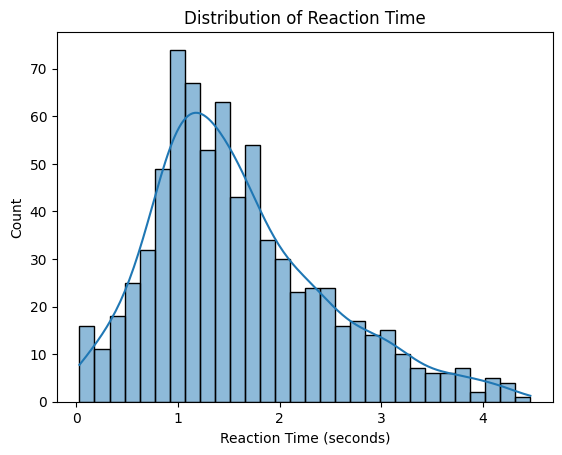

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

train['reaction_time'] = train['time_of_event'] - train['time_of_alert']

sns.histplot(train['reaction_time'].dropna(), bins=30, kde=True)
plt.title('Distribution of Reaction Time')
plt.xlabel('Reaction Time (seconds)')
plt.show()

In [7]:
import cv2

#get frames from videos
def extract_frames(video_path, num_frames):
    #open video
    cap = cv2.VideoCapture(video_path)
    
    #get total num of frames
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    #determine step size
    #divide total num of frames by provided num of frames
    #calculates how many frames to skip between each extracted frame
    step = max(total_frames // num_frames, 1)

    #initialize frames
    frames = []

    #loop through video frames w/ step size
    for i in range(0, total_frames, step):
        #set current frame position
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)

        #read frame
        ret, frame = cap.read()

        #if not read successfully...
        if not ret:
            break
            
        #convert BGR to RGB for display in matplotlib
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        #add frame to frames list
        frames.append(frame)

    #release video once all frames are processed 
    cap.release()
    return frames

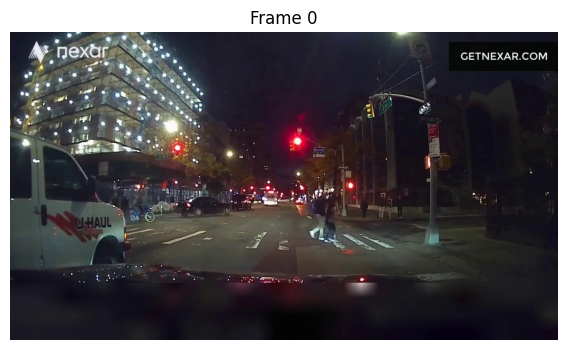

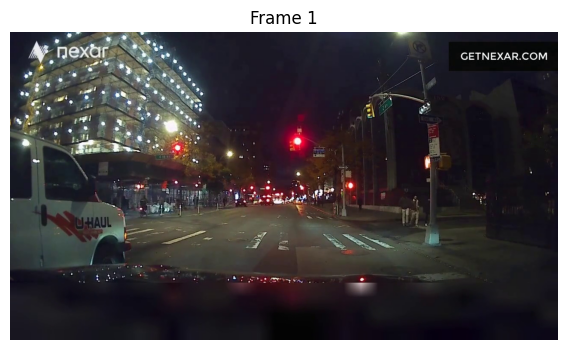

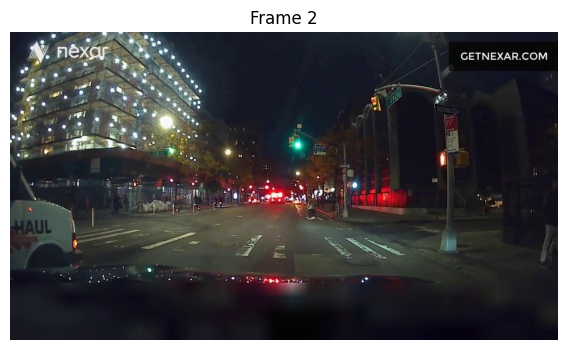

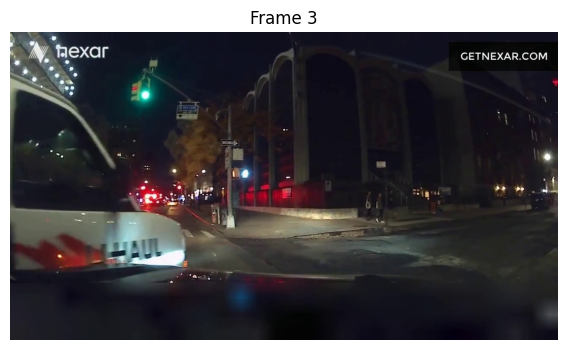

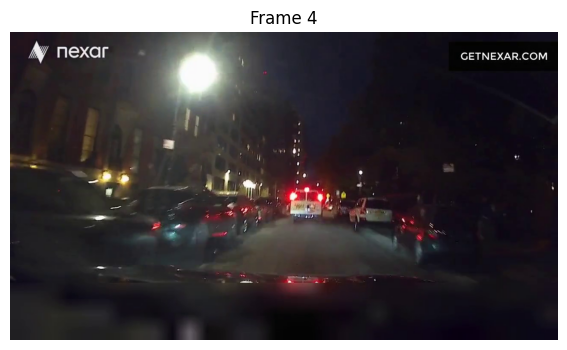

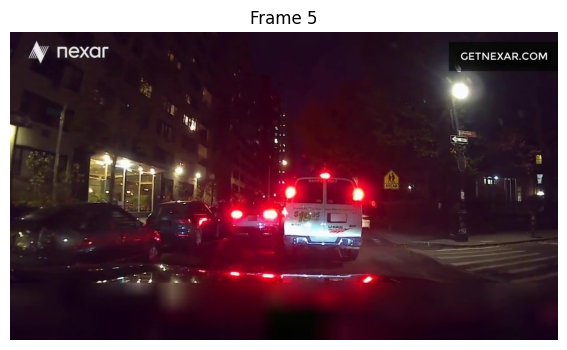

In [8]:
#example:
video_path = '/kaggle/input/nexar-collision-prediction/train/00000.mp4'
frames = extract_frames(video_path, 5)

#display frames
for i, frame in enumerate(frames):
    plt.figure(figsize=(8,4))
    plt.imshow(frame)
    plt.title(f'Frame {i}')
    plt.axis('off')
    plt.show()

In [9]:
#https://docs.opencv.org/4.x/d0/d49/tutorial_moments.html
#analyze frames


In [10]:
import cv2
import numpy as np

def compute_optical_flow(video_path):
    cap = cv2.VideoCapture(video_path)
    ret, prev_frame = cap.read()
    prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)

    flows = []
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        flow = cv2.calcOpticalFlowFarneback(prev_gray, gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        flows.append(flow.mean())  # Store mean flow magnitude
        prev_gray = gray
    
    cap.release()
    return np.array(flows)

# Example usage:
video_path = '/kaggle/input/nexar-collision-prediction/train/00000.mp4'
flow_features = compute_optical_flow(video_path)
print(flow_features.shape)  # Check extracted features

(1157,)


In [11]:
def extract_edges(video_path, num_frames=10):
    cap = cv2.VideoCapture(video_path)
    frames = []
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    step = max(total_frames // num_frames, 1)

    for i in range(0, total_frames, step):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        edges = cv2.Canny(gray, 100, 200)
        frames.append(edges)
    
    cap.release()
    return np.array(frames)

# Example usage:
edges = extract_edges(video_path)
print(edges.shape)


(11, 720, 1280)


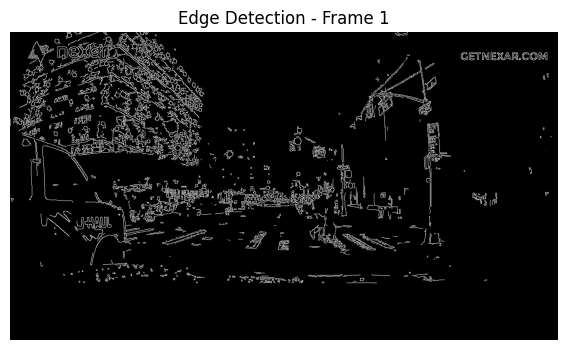

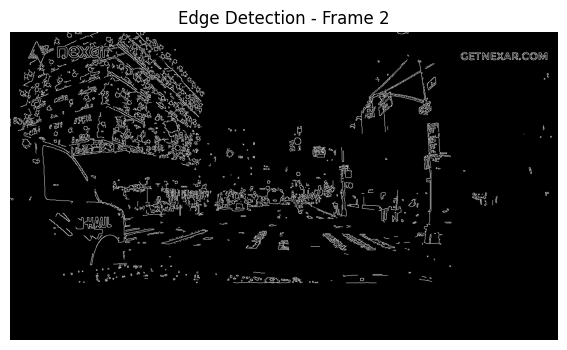

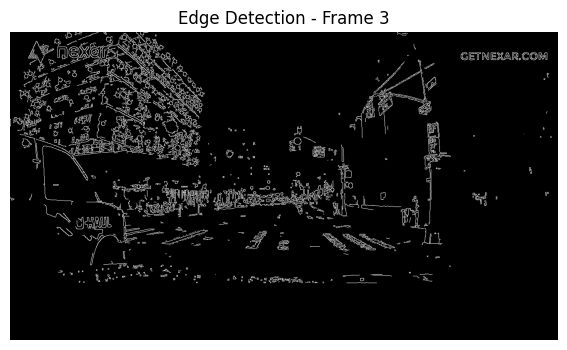

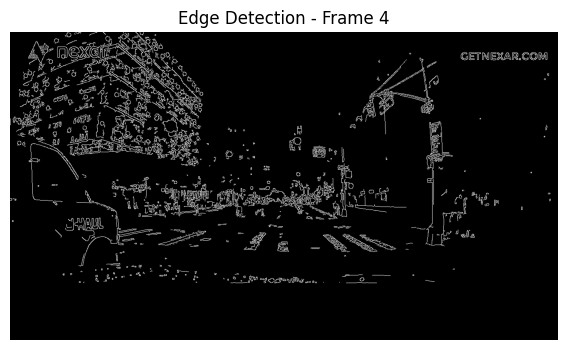

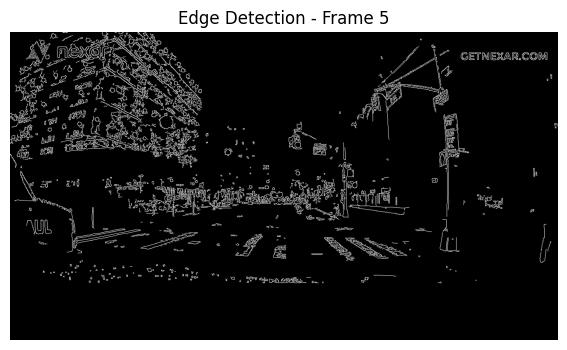

In [12]:
import matplotlib.pyplot as plt

# Display first 5 extracted edge frames
for i in range(min(5, edges.shape[0])):  
    plt.figure(figsize=(8, 4))
    plt.imshow(edges[i], cmap='gray')  # Show edge-detected frame
    plt.title(f'Edge Detection - Frame {i+1}')
    plt.axis('off')
    plt.show()


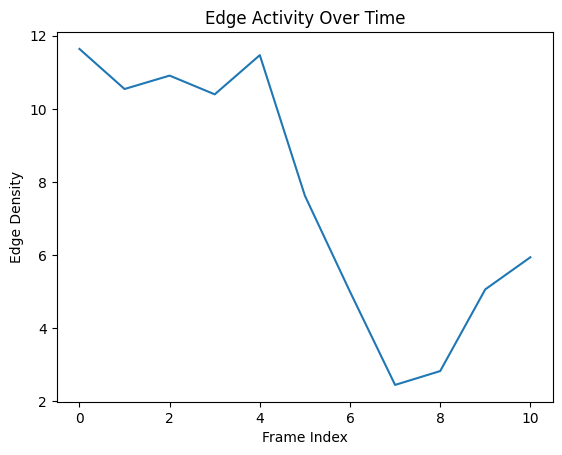

In [13]:
edge_density = [frame.sum() / (720 * 1280) for frame in edges]  # Normalize by total pixels
plt.plot(edge_density)
plt.xlabel("Frame Index")
plt.ylabel("Edge Density")
plt.title("Edge Activity Over Time")
plt.show()


In [14]:
import os
video_dir = "/kaggle/input/nexar-collision-prediction/train/"
video_files = sorted([f for f in os.listdir(video_dir) if f.endswith(".mp4")])
video_ids = [os.path.splitext(f)[0] for f in video_files]

print("Found", len(video_ids), "videos.")
print("First 5 video IDs:", video_ids[:5])


Found 1500 videos.
First 5 video IDs: ['00000', '00003', '00004', '00005', '00006']


In [29]:
video_features = []

labels_df = pd.read_csv("/kaggle/input/nexar-collision-prediction/train.csv")
labels_df.rename(columns={'id': 'video_id'}, inplace=True)
labels_df['video_id'] = labels_df['video_id'].astype(str).str.zfill(5)

video_ids = labels_df['video_id'].tolist()

for video_id in video_ids[:5]:  //debugging 
    video_path = f"/kaggle/input/nexar-collision-prediction/train/{video_id}.mp4"
    
    edge_frames = extract_edges(video_path, num_frames=3)
    edge_density = [frame.sum() / frame.size for frame in edge_frames]

    summary = {
        'video_id': video_id,
        'edge_mean': np.mean(edge_density) if len(edge_density) > 0 else 0,
        'edge_std': np.std(edge_density) if len(edge_density) > 0 else 0,
        'edge_max': np.max(edge_density) if len(edge_density) > 0 else 0,
        'flow_mean': 0,
        'flow_std': 0,
        'flow_max': 0
    }

    video_features.append(summary)

features_df = pd.DataFrame(video_features)



In [32]:
merged_df = features_df.merge(labels_df[['video_id', 'target']], on='video_id')
print("Merged shape:", merged_df.shape)

if len(merged_df) > 0:
    X = merged_df.drop(columns=['video_id', 'target'])
    y = merged_df['target']

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, y)

    print("Model trained ")
else:
    print(" empty .")


Merged shape: (5, 8)
Model trained 


In [31]:
print("Features video IDs:", features_df['video_id'].tolist())
print("Label video IDs:", labels_df['video_id'].tolist()[:10])



Features video IDs: ['01924', '00822', '01429', '00208', '01904']
Label video IDs: ['01924', '00822', '01429', '00208', '01904', '00072', '01486', '01171', '00128', '01518']
